# Comparative Analysis: Trial Length & Flexibility Across Experimental Setups

This notebook extracts, processes, and plots training dynamics across multiple experimental setups from **Weights & Biases (W&B)** and local cache files:
1. **Experimental Setups**:
   - **Baseline (No-Context)**: `ymaze_nocontext` baseline runs (5 seeds, `r.sca_0.1_l.rat_0.0002`).
   - **DG Modulations**: `DG: Sigmoid`, `DG: Concat`, `DG: Multiply` (`ENC_DECymaze_new_instr`, `l.rat=0.0001`).
   - **Decoder + DG Modulations (Cocktail / Ablation)**: `Decoder + DG: Concat+Sigmoid`, `Decoder + DG: Concat+Multiply`.
2. **Proper Isolated Metric Fetching**:
   - Fetches `len/len` and `custom/flexibility` in dedicated, independent 2-column W&B history queries (`[metric, step_col]`).
   - Guarantees 100% data density (eliminating W&B downsampling `NaN` dropouts).
   - Allows runs lacking flexibility (e.g., No-Context baseline) to cleanly compute Trial Length without errors or being skipped.
3. **Standard Error of the Mean (SEM)**:
   $$\text{SEM} = \frac{\sigma}{\sqrt{N}} = \frac{\sqrt{\text{Var}}}{\sqrt{N}}$$
4. **Individual Separate Figures**:
   - Dedicated publication-standard figure for **Trial Length** (Steps / Trial).
   - Dedicated publication-standard figure for **Flexibility** (Flexibility Index).


In [4]:
import sys
print(sys.executable)
%pip install matplotlib wandb

/home/erten/miniconda3/envs/ymaze/bin/python
/bin/bash: /home/erten/miniconda3/envs/ymaze/lib/libtinfo.so.6: no version information available (required by /bin/bash)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 73.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 81.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 64.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib] 5/6 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
import wandb

# ------------------------------------------------------------------------------
# 1. PUBLICATION SETTINGS (Physical sizing, font sizes, clean borders)
# ------------------------------------------------------------------------------
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
mpl.rcParams['lines.linewidth'] = 1.4
mpl.rcParams['savefig.transparent'] = True
mpl.rcParams['savefig.bbox'] = 'tight'

# Custom publication color palette
CONDITION_COLORS = {
    "No-Context": "#333333",                       # Charcoal
    "DG: Sigmoid": "#1f77b4",                      # Blue
    "DG: Concat": "#17becf",                       # Cyan / Teal
    "Decoder + DG: Concat+Sigmoid": "#ff7f0e",    # Orange
    "Decoder": "#9467bd",   # Purple
}

FALLBACK_COLORS = ["#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]

def format_compact_label(label, n):
    """Wrap long condition labels into multiple lines to keep legend narrow."""
    if "Decoder + DG:" in label:
        sub = label.replace("Decoder + DG: ", "")
        return f"Decoder + DG:\n{sub} (n={n})"
    return f"{label} (n={n})"

def style_axes_and_legend(ax, legend_loc='upper left', bbox_to_anchor=(1.02, 1.0)):
    """Apply publication standards: despine top/right and format compact outside legend."""
    ax.axes.spines[['top', 'right']].set_visible(False)
    legend = ax.get_legend()
    if legend:
        legend.set_frame_on(False)
        legend.set_bbox_to_anchor(bbox_to_anchor)
        legend.set_loc(legend_loc)
        for text in legend.get_texts():
            text.set_fontsize(7.5)
            text.set_linespacing(0.9)


OpenBLAS blas_thread_init: pthread_create failed for thread 49 of 60: Resource temporarily unavailable
OpenBLAS blas_thread_init: RLIMIT_NPROC 1544902 current, 1544902 max
OpenBLAS blas_thread_init: pthread_create failed for thread 50 of 60: Resource temporarily unavailable
OpenBLAS blas_thread_init: RLIMIT_NPROC 1544902 current, 1544902 max
OpenBLAS blas_thread_init: pthread_create failed for thread 51 of 60: Resource temporarily unavailable
OpenBLAS blas_thread_init: RLIMIT_NPROC 1544902 current, 1544902 max
OpenBLAS blas_thread_init: pthread_create failed for thread 52 of 60: Resource temporarily unavailable
OpenBLAS blas_thread_init: RLIMIT_NPROC 1544902 current, 1544902 max
OpenBLAS blas_thread_init: pthread_create failed for thread 53 of 60: Resource temporarily unavailable
OpenBLAS blas_thread_init: RLIMIT_NPROC 1544902 current, 1544902 max
OpenBLAS blas_thread_init: pthread_create failed for thread 54 of 60: Resource temporarily unavailable
OpenBLAS blas_thread_init: RLIMIT_NPR

KeyboardInterrupt: 

## 1. Experimental Setups Configuration

Defines projects, matching rules, learning rate filters, and caching configurations.

In [3]:
# Default W&B Entity (Team / Username)
WANDB_ENTITY = "xiaoxionglin-bernstein-center-freiburg"

# Project names
PROJECT_NOCONTEXT = "ymaze_nocontext"
PROJECT_ORACLE = "ENC_DECymaze_norew_instr"
PROJECT_COCKTAIL = "NEWymaze_norew_instr"

# ==============================================================================
# EXPERIMENTAL SETUPS DEFINITION
# ==============================================================================
EXPERIMENTAL_SETUPS = {
    # Baseline: 5 exact seeds from ymaze_nocontext
    "No-Context": {
        "project": PROJECT_NOCONTEXT,
        "entity": WANDB_ENTITY,
        "run_names": [
            "05_noINSTR_see_1111_r.sca_0.1_l.rat_0.0002",
            "14_noINSTR_see_2222_r.sca_0.1_l.rat_0.0002",
            "23_noINSTR_see_3333_r.sca_0.1_l.rat_0.0002",
            "32_noINSTR_see_4444_r.sca_0.1_l.rat_0.0002",
            "41_noINSTR_see_5555_r.sca_0.1_l.rat_0.0002",
        ],
        "is_context": False,
    },
    # DG Context Modulations (ENC_DECymaze_new_instr)
    "DG: Sigmoid": {
        "project": PROJECT_ORACLE,
        "entity": WANDB_ENTITY,
        "include_any": ["d.c.mod_sigmoid", "dg_sigmoid", "sigmoid", "encoderonly"],
        "exclude": ["concat", "multiply", "decoderonly", "ablation"],
        "is_context": True,
    },
    #"DG: Multiply": {
    #    "project": PROJECT_ORACLE,
    #    "entity": WANDB_ENTITY,
    #    "include_any": ["d.c.mod_multiply", "dg_multiply", "multiply"],
    #    "exclude": ["concat", "sigmoid", "cocktail"],
    #    "is_context": True,
    #},
    "DG: Concat": {
        "project": PROJECT_ORACLE,
        "entity": WANDB_ENTITY,
        "include_any": ["d.c.mod_concat", "dg_concat", "concat", "encoderonly"],
        "exclude": ["sigmoid", "multiply", "decoderonly", "ablation"],
        "is_context": True,
    },
    # Joint / Cocktail Modulations
    "Decoder + DG: Concat+Sigmoid": {
        "project": PROJECT_COCKTAIL,
        "entity": WANDB_ENTITY,
        "include_all": ["sigmoid"],
        "is_context": True,
        "target_lrat": "2e-05",
        "target_rsca": "0.1",
        "target_nicoe": "200"
    },
    #"Decoder + DG: Concat+Multiply": {
    #    "project": PROJECT_ORACLE,
    #    "entity": WANDB_ENTITY,
    #    "include_all": ["concat", "multiply"],
    #    "is_context": True,
    #},

    "Decoder":{
        "project": PROJECT_ORACLE,
        "entity": WANDB_ENTITY,
        "include_any": ["decoderonly", "enter"],
        "exclude": ["FiLM", "additive", "ablation"],
        "is_context": True,
        "target_lrat": "2e-05",
        "target_rsca": "0.1",
    },
}

# ==============================================================================
# ENVIRONMENT & RESAMPLING PARAMETERS
# ==============================================================================
NUM_POLICIES = 4           # 4 policies per seed (0, 1, 2, 3)
TRIALS_PER_EPISODE = 75    # 75 trials per episode (216k / 75 = 2880 steps/trial max)

NUM_RESAMPLE_POINTS = 500  # Number of points along interpolated step grid
MAX_STEP = 200e6            # Horizon to plot (50M steps)

CACHE_FILE = "cache_experiments_data.pkl"
CACHE_FILE_COCKTAIL = "cache_experiments_data_cocktail.pkl"
FORCE_REFETCH = False      # Set to True to re-query live W&B


## 2. Proper Per-Policy Isolated Metric Extraction Helpers

Fetches each metric (`len/len` and `custom/flexibility`) in its own isolated 2-column W&B query (`[metric, step_col]`). This avoids downsampling `NaN` dropouts and allows baseline runs without flexibility to be cleanly extracted.

In [4]:
def resample_series(df, step_col, metric_col, target_steps):
    """Clean, sort, deduplicate and interpolate onto target_steps; mask out extrapolation."""
    clean = df[[step_col, metric_col]].dropna().sort_values(step_col)
    clean = clean.drop_duplicates(subset=step_col, keep="last")
    if len(clean) < 2 or clean[step_col].nunique() < 2:
        return None
    max_step = clean[step_col].max()
    interp_vals = np.interp(target_steps, clean[step_col].values, clean[metric_col].values)
    # Mask out extrapolation past when the run actually stopped
    interp_vals[target_steps > max_step] = np.nan
    return interp_vals


def fetch_policy_average_for_seed(run, target_steps, num_policies=NUM_POLICIES, 
                                  trials_per_ep=TRIALS_PER_EPISODE):
    """
    Fetches each metric independently with its own step column:
      - [f"{p}/len/len", f"{p}/global_step"]
      - [f"{p}/custom/flexibility", f"{p}/global_step"]
    Guarantees 100% data density (no NaNs from cross-metric downsampling).
    """
    policy_tl = []
    policy_flex = []

    for p in range(num_policies):
        step_col = f"{p}/global_step"
        len_col = f"{p}/len/len"
        flex_col = f"{p}/custom/flexibility"

        # 1. Fetch Trial Length (ONLY len/len and its step_col)
        try:
            hist_tl = run.history(keys=[len_col, step_col], samples=1500, pandas=True)
            if not hist_tl.empty and len_col in hist_tl.columns and step_col in hist_tl.columns:
                hist_tl[f"{p}/trial_len"] = hist_tl[len_col] / trials_per_ep
                tl_resampled = resample_series(hist_tl, step_col, f"{p}/trial_len", target_steps)
                if tl_resampled is not None:
                    policy_tl.append(tl_resampled)
        except Exception as exc:
            print(f"      [Warning] Policy {p} TL fetch failed for {run.name}: {exc}")

        # 2. Fetch Flexibility (ONLY flexibility and its step_col)
        try:
            hist_flex = run.history(keys=[flex_col, step_col], samples=1500, pandas=True)
            if not hist_flex.empty and flex_col in hist_flex.columns and step_col in hist_flex.columns:
                flex_resampled = resample_series(hist_flex, step_col, flex_col, target_steps)
                if flex_resampled is not None:
                    policy_flex.append(flex_resampled)
        except Exception as exc:
            print(f"      [Warning] Policy {p} Flex fetch failed for {run.name}: {exc}")

    if not policy_tl or not policy_flex:
        return None, None

    # Level 1: Average across all available policies for this seed
    seed_tl_avg = np.nanmean(policy_tl, axis=0)
    seed_flex_avg = np.nanmean(policy_flex, axis=0)

    return seed_tl_avg, seed_flex_avg


## 3. Data Retrieval, Multiple Pickle Caches & SEM Calculation

Checks run matches, supports loading & merging from multiple pickle cache files (`cache_experiments_data.pkl` and `cache_experiments_data_cocktail.pkl`), and calculates the **Standard Error of the Mean (SEM)** across seeds.

In [5]:
def check_run_match(run, setup_info):
    """Checks if a run matches the criteria for a setup, enforcing l.rat=0.0001 for context runs."""
    name_lower = run.name.lower()
    exp_lower = str(run.config.get("experiment", "")).lower()
    dec_mod = str(run.config.get("Decoder_context_mod", "")).lower()
    dg_mod = str(run.config.get("DG_context_mod", "")).lower()
    instr_mod = str(run.config.get("INSTR_modulation", "")).lower()

    blob = f"{name_lower} {exp_lower} {dec_mod} {dg_mod} {instr_mod}"

    # 1. Match explicit run names if provided
    run_name_list = setup_info.get("run_names", [])
    if run_name_list:
        return any(target.lower() in name_lower for target in run_name_list)

    # 2. Strict learning rate filter: if 'l.rat' is in run name, only accept 0.0001 for context runs
    target_lrat = setup_info.get("target_lrat", "2e-05" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE  or setup_info.get("project") == PROJECT_COCKTAIL else None)
    if target_lrat and "l.rat" in name_lower:
        if not ("0.0001" in name_lower or "1e-4" in name_lower or "1e-04" in name_lower):
            return False  # Filters out 0.0002, 2e-05, etc.
    # 3. Optional coefficient / reward scale filters
    target_coef = setup_info.get("target_coef", "200" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE or setup_info.get("project") == PROJECT_COCKTAIL else None)
    if target_coef and "n.i.coe" in name_lower:
        if str(target_coef) not in name_lower:
            return False
    target_rsa = setup_info.get("target_rsa", "0.1" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE or setup_info.get("project") == PROJECT_COCKTAIL else None)
    if target_rsa and "r.sca" in name_lower:
        if str(target_rsa) not in name_lower:
            return False
    # 3. Check exclusions
    for exc in setup_info.get("exclude", []):
        if exc.lower() in blob:
            return False

    # 4. Check include_all
    include_all = setup_info.get("include_all", [])
    if include_all:
        if not all(pattern.lower() in blob for pattern in include_all):
            return False

    # 5. Check include_any
    include_any = setup_info.get("include_any", [])
    if include_any:
        if not any(pattern.lower() in blob for pattern in include_any):
            return False

    return True


results = {}
target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
results["_target_steps"] = target_steps

# Check if loading from local pickle cache(s)
loaded_from_cache = False
if not FORCE_REFETCH:
    # Case A: Two separate pkl files (standard cache + cocktail cache)
    if os.path.exists(CACHE_FILE) and os.path.exists(CACHE_FILE_COCKTAIL):
        print(f"Loading and merging cached data from {CACHE_FILE} and {CACHE_FILE_COCKTAIL}...")
        with open(CACHE_FILE, "rb") as f:
            data_std = pickle.load(f)
        with open(CACHE_FILE_COCKTAIL, "rb") as f:
            data_cocktail = pickle.load(f)

        target_steps = data_std.get("_target_steps", target_steps)
        results["_target_steps"] = target_steps

        # 1. Standard cache: DG: Sigmoid, DG: Concat, DG: Multiply
        for k in ["DG: Sigmoid", "DG: Concat", "Decoder: Enter"]:
            if k in data_std:
                results[k] = data_std[k]
        

        # 2. Cocktail cache: No-Context + renamed joint modulations
        if "No-Context" in data_cocktail:
            results["No-Context"] = data_cocktail["No-Context"]
        if "DG: Sigmoid" in data_cocktail:
            results["Decoder + DG: Concat+Sigmoid"] = data_cocktail["DG: Sigmoid"]

        loaded_from_cache = True
        print("Successfully merged cached setups:", [k for k in results if not k.startswith("_")])

    elif os.path.exists(CACHE_FILE):
        print(f"Loading cached data from {CACHE_FILE}...")
        with open(CACHE_FILE, "rb") as f:
            results = pickle.load(f)
        target_steps = results.get("_target_steps", target_steps)
        loaded_from_cache = True
        print("Loaded setups from cache:", [k for k in results if not k.startswith("_")])

if not loaded_from_cache:
    print("Querying live W&B data across projects...")
    api = wandb.Api(timeout=60)
    project_runs_cache = {}

    for setup_label, setup_info in EXPERIMENTAL_SETUPS.items():
        proj = setup_info.get("project")
        ent = setup_info.get("entity", WANDB_ENTITY)
        full_proj_path = f"{ent}/{proj}"

        print(f"\n=== Processing Setup: {setup_label} ===")
        print(f"    W&B Project: {full_proj_path}")

        if full_proj_path not in project_runs_cache:
            try:
                print(f"    Fetching runs list from {full_proj_path}...")
                project_runs_cache[full_proj_path] = list(api.runs(full_proj_path))
                print(f"    Total runs in {proj}: {len(project_runs_cache[full_proj_path])}")
            except Exception as e:
                print(f"    [Error] Failed to fetch project {full_proj_path}: {e}. Skipping.")
                continue

        proj_runs = project_runs_cache[full_proj_path]
        matched_runs = [r for r in proj_runs if check_run_match(r, setup_info)]
        print(f"    Matched {len(matched_runs)} seed run(s):")
        for r in matched_runs:
            seed_val = r.config.get("seed", "unknown")
            print(f"      - {r.name} (seed={seed_val})")

        seed_tl_list = []
        seed_flex_list = []

        for run in matched_runs:
            tl_seed_avg, flex_seed_avg = fetch_policy_average_for_seed(run, target_steps)
            if tl_seed_avg is not None:
                seed_tl_list.append(tl_seed_avg)
            if flex_seed_avg is not None:
                seed_flex_list.append(flex_seed_avg)

        n_tl = len(seed_tl_list)
        n_flex = len(seed_flex_list)
        if n_tl == 0 and n_flex == 0:
            print(f"    [Warning] No valid data extracted for {setup_label}. Skipping.")
            continue

        # Aggregate Trial Length (Mean ± SEM)
        if n_tl > 0:
            seeds_tl = np.array(seed_tl_list)
            tl_avg = np.nanmean(seeds_tl, axis=0)
            valid_n_tl = np.sum(~np.isnan(seeds_tl), axis=0)
            tl_var = np.nanvar(seeds_tl, axis=0, ddof=1) if n_tl > 1 else np.zeros_like(tl_avg)
            tl_sem = np.where(valid_n_tl > 1, np.sqrt(tl_var) / np.sqrt(valid_n_tl), np.zeros_like(tl_var))
        else:
            seeds_tl, tl_avg, tl_sem = None, None, None

        # Aggregate Flexibility (Mean ± SEM)
        if n_flex > 0:
            seeds_flex = np.array(seed_flex_list)
            flex_avg = np.nanmean(seeds_flex, axis=0)
            valid_n_flex = np.sum(~np.isnan(seeds_flex), axis=0)
            flex_var = np.nanvar(seeds_flex, axis=0, ddof=1) if n_flex > 1 else np.zeros_like(flex_avg)
            flex_sem = np.where(valid_n_flex > 1, np.sqrt(flex_var) / np.sqrt(valid_n_flex), np.zeros_like(flex_var))
        else:
            seeds_flex, flex_avg, flex_sem = None, None, None

        results[setup_label] = {
            "n_seeds_tl": n_tl,
            "n_seeds_flex": n_flex,
            "n_seeds": max(n_tl, n_flex),
            "seeds_tl": seeds_tl,
            "seeds_flex": seeds_flex,
            "tl_avg": tl_avg,
            "tl_sem": tl_sem,
            "flex_avg": flex_avg,
            "flex_sem": flex_sem,
        }
        print(f"    -> Aggregated {setup_label}: TL seeds={n_tl}, Flex seeds={n_flex}.")

    # Cache results
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(results, f)
    print(f"\nSaved aggregated results to {CACHE_FILE}.")


Loading cached data from cache_experiments_data.pkl...
Loaded setups from cache: ['No-Context', 'DG: Sigmoid', 'DG: Concat', 'Decoder + DG: Concat+Sigmoid', 'Decoder']


## 4. Separate Publication Plot: Trial Length (Steps / Trial)

Plots the central **Mean** line with **± SEM** shaded band for trial length as an individual standalone figure.

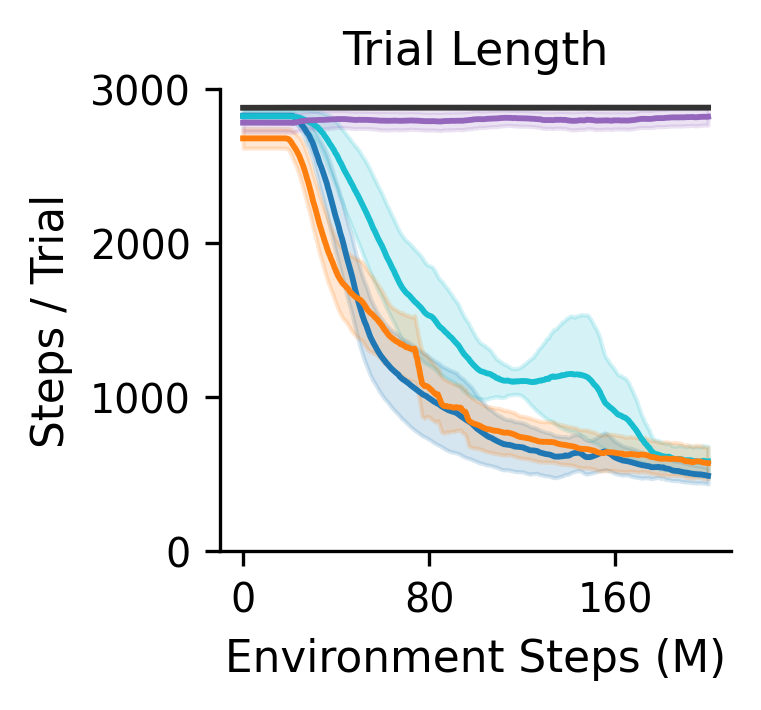

Saved Trial Length figure to trial_length_comparison.pdf and .png


In [34]:
step_axis_millions = target_steps / 1e6
active_setups = [k for k in results if not k.startswith("_")]

# ------------------------------------------------------------------------------
# TRIAL LENGTH PLOT (Individual Standalone Figure)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.2, 2), dpi=300)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    if data.get("tl_avg") is None or data.get("tl_sem") is None:
        continue

    col = CONDITION_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n = data.get("n_seeds_tl", data.get("n_seeds", 0))
    label_text = format_compact_label(setup_label, n)

    ax.plot(step_axis_millions, data["tl_avg"], color=col, label=label_text)
    ax.fill_between(
        step_axis_millions,
        np.clip(data["tl_avg"] - data["tl_sem"], 0, None),
        data["tl_avg"] + data["tl_sem"],
        color=col,
        alpha=0.18,
    )

ax.set_title("Trial Length", fontsize=11, pad=6)
ax.set_ylabel("Steps / Trial", fontsize=10.5)
ax.set_xlabel("Environment Steps (M)", fontsize=10.5)
ax.set_ylim(0, 3000)
ax.set_yticks([0, 1000, 2000, 3000])
ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax.tick_params(axis="both", labelsize=9.5)

#ax.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax)

plt.savefig("trial_length_comparison.pdf", dpi=300)
plt.savefig("trial_length_comparison.png", dpi=300)
plt.show()
print("Saved Trial Length figure to trial_length_comparison.pdf and .png")


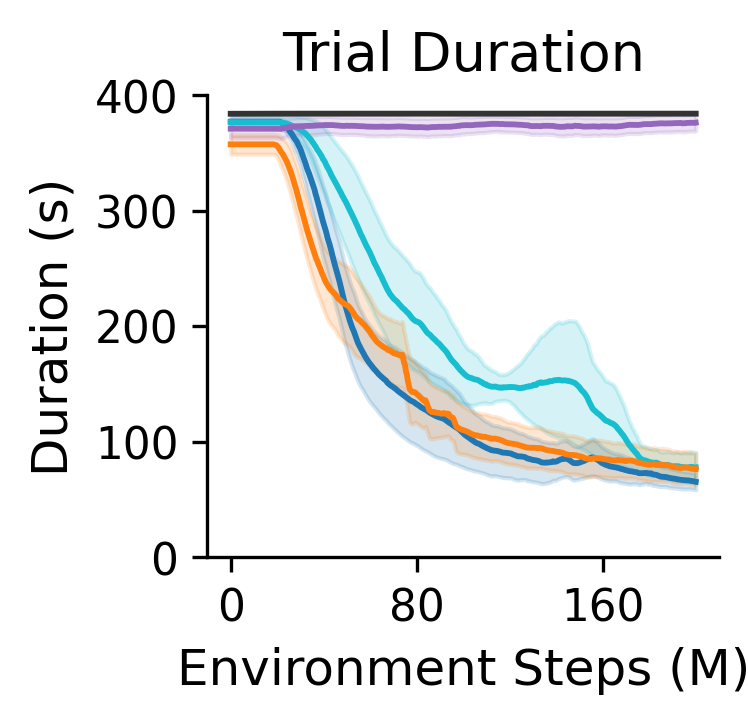

Saved Trial Duration figure to trial_duration_comparison.pdf and .png


In [10]:
step_axis_millions = target_steps / 1e6
active_setups = [k for k in results if not k.startswith("_")]

# ------------------------------------------------------------------------------
# TRIAL DURATION PLOT (Converted to seconds: 8 frameskip / 60 FPS)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.2, 2), dpi=300)

# 1 step = 8 engine frames / 60 FPS = 0.1333 seconds
SECONDS_PER_STEP = 8 / 60  

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    if data.get("tl_avg") is None or data.get("tl_sem") is None:
        continue

    col = CONDITION_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n = data.get("n_seeds_tl", data.get("n_seeds", 0))
    label_text = format_compact_label(setup_label, n)

    # Convert steps to seconds
    tl_sec = data["tl_avg"] * SECONDS_PER_STEP
    tl_sem_sec = data["tl_sem"] * SECONDS_PER_STEP

    ax.plot(step_axis_millions, tl_sec, color=col, label=label_text)
    ax.fill_between(
        step_axis_millions,
        np.clip(tl_sec - tl_sem_sec, 0, None),
        tl_sec + tl_sem_sec,
        color=col,
        alpha=0.18,
    )

ax.set_title("Trial Duration", fontsize=13, pad=6)
ax.set_ylabel("Duration (s)", fontsize=12)
ax.set_xlabel("Environment Steps (M)", fontsize=12)

# 3000 steps * (8/60) = 400 seconds
ax.set_ylim(0, 400)
ax.set_yticks([0, 100, 200, 300, 400])
ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax.tick_params(axis="both", labelsize=10.5)

#ax.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax)

plt.savefig("trial_duration_comparison.pdf", dpi=300)
plt.savefig("trial_duration_comparison.png", dpi=300)
plt.show()
print("Saved Trial Duration figure to trial_duration_comparison.pdf and .png")

## 5. Separate Publication Plot: Flexibility (Flexibility Index)

Plots the central **Mean** line with **± SEM** shaded band for flexibility as an individual standalone figure.

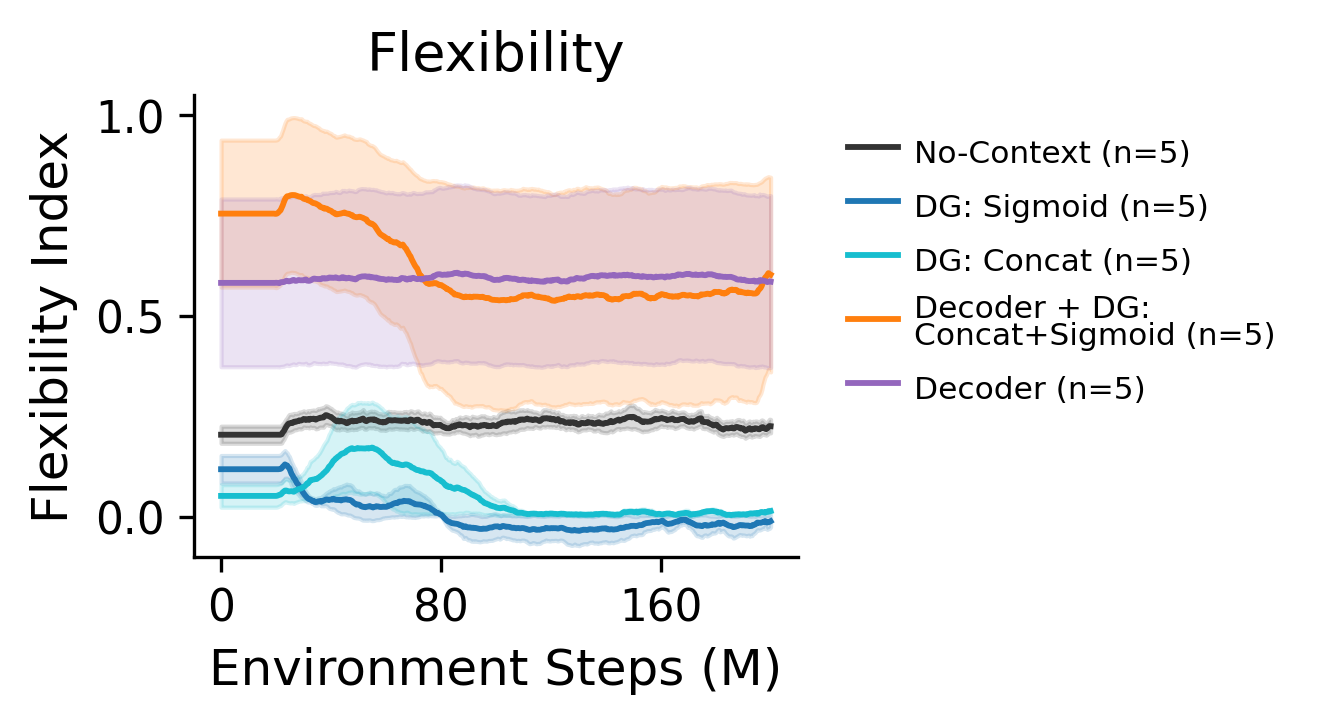

Saved Flexibility figure to flexibility_comparison.pdf and .png


In [9]:
# ------------------------------------------------------------------------------
# FLEXIBILITY PLOT (Individual Standalone Figure)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.6, 2), dpi=300)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    if data.get("flex_avg") is None or data.get("flex_sem") is None:
        continue

    col = CONDITION_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n = data.get("n_seeds_flex", data.get("n_seeds", 0))
    label_text = format_compact_label(setup_label, n)

    ax.plot(step_axis_millions, data["flex_avg"], color=col, label=label_text)
    ax.fill_between(
        step_axis_millions,
        data["flex_avg"] - data["flex_sem"],
        data["flex_avg"] + data["flex_sem"],
        color=col,
        alpha=0.18,
    )

ax.set_title("Flexibility", fontsize=13, pad=6)
ax.set_ylabel("Flexibility Index", fontsize=12)
ax.set_xlabel("Environment Steps (M)", fontsize=12)
ax.set_ylim(-0.1, 1.05)
ax.set_yticks([0, 0.5, 1.0])
ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax.tick_params(axis="both", labelsize=10.5)

ax.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax)

plt.savefig("flexibility_comparison.pdf", dpi=300)
plt.savefig("flexibility_comparison.png", dpi=300)
plt.show()
print("Saved Flexibility figure to flexibility_comparison.pdf and .png")


## 6. Detailed Diagnostics: Individual Seed Traces & SEM Curves

Inspect individual seed curves (faint traces) and exact SEM trajectories over training steps.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 4.0), dpi=300, sharex=True)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    col = CONDITION_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n_tl = data.get("n_seeds_tl", data.get("n_seeds", 0))
    n_flex = data.get("n_seeds_flex", data.get("n_seeds", 0))

    # Row 0, Col 0: Trial Length Mean + Seeds
    if data.get("tl_avg") is not None:
        axes[0, 0].plot(step_axis_millions, data["tl_avg"], color=col, label=f"{setup_label} (n={n_tl})")
        if data.get("seeds_tl") is not None:
            for s in range(len(data["seeds_tl"])):
                axes[0, 0].plot(step_axis_millions, data["seeds_tl"][s], color=col, alpha=0.18, linewidth=0.7)

    # Row 0, Col 1: Flexibility Mean + Seeds
    if data.get("flex_avg") is not None:
        axes[0, 1].plot(step_axis_millions, data["flex_avg"], color=col, label=f"{setup_label} (n={n_flex})")
        if data.get("seeds_flex") is not None:
            for s in range(len(data["seeds_flex"])):
                axes[0, 1].plot(step_axis_millions, data["seeds_flex"][s], color=col, alpha=0.18, linewidth=0.7)

    # Row 1, Col 0: Trial Length SEM
    if data.get("tl_sem") is not None:
        axes[1, 0].plot(step_axis_millions, data["tl_sem"], color=col, label=setup_label)

    # Row 1, Col 1: Flexibility SEM
    if data.get("flex_sem") is not None:
        axes[1, 1].plot(step_axis_millions, data["flex_sem"], color=col, label=setup_label)

axes[0, 0].set_title("Trial Length (Steps / Trial)", pad=4)
axes[0, 0].set_ylabel("Steps / Trial")
axes[0, 0].set_ylim(0, 3000)
axes[0, 0].legend()
style_axes_and_legend(axes[0, 0], bbox_to_anchor=(1.02, 1))

axes[0, 1].set_title("Flexibility", pad=4)
axes[0, 1].set_ylabel("Flexibility Index")
axes[0, 1].legend()
style_axes_and_legend(axes[0, 1], bbox_to_anchor=(1.02, 1))

axes[1, 0].set_title("Trial Length SEM", pad=4)
axes[1, 0].set_ylabel("SEM (Steps)")
axes[1, 0].set_xlabel("Environment Steps (M)")
axes[1, 0].legend()
style_axes_and_legend(axes[1, 0], bbox_to_anchor=(1.02, 1))

axes[1, 1].set_title("Flexibility SEM", pad=4)
axes[1, 1].set_ylabel("SEM")
axes[1, 1].set_xlabel("Environment Steps (M)")
axes[1, 1].legend()
style_axes_and_legend(axes[1, 1], bbox_to_anchor=(1.02, 1))

plt.savefig("breakdown_averages_and_sem.pdf", dpi=300)
plt.savefig("breakdown_averages_and_sem.png", dpi=300)
plt.show()
print("Saved breakdown diagnostics to breakdown_averages_and_sem.pdf and .png")
